# Idea 11 - Why Platforms Excel

**Machines, Platforms, Crowds, Chapter 8**

The chapter gives three mechanisms by which platforms beat incumbents. They
raise the utilisation of perishable inventory. They attack information
asymmetry, which is the deeper claim, because a platform is less a matching
technology than an institution for solving Akerlof's lemons problem. And they
price along the demand curve in ways their own suppliers find painful and
cannot match.

The pricing argument is the distinctive one. An incumbent estimates demand
from the range of prices it has historically charged, which is the flat,
high-price end of the curve. If the true curve is a decaying exponential, the
volume far down it is enormous and invisible from where the incumbent is
standing, so it concludes a low price destroys revenue. Under zero marginal
cost the arithmetic runs the other way. On a two-sided platform it runs
further still: lower the price on the elastic side, raise it on the inelastic
side, and where the cross-elasticity is large enough, a negative price is
rational.

### What is testable here

1. **Utilisation.** Airline load factor is the longest public series on the
   use of perishable capacity. Airlines are not platforms, so this measures
   the size of the prize rather than any platform's effect.
2. **Displacement.** E-commerce as a share of retail sales, against employment
   in the incumbent format it replaced. This is the one place the chapter's
   claim shows up cleanly in national statistics.
3. **The extrapolation trap.** Simulated, with a planted answer. If the true
   demand curve is exponential and an incumbent fits a line through the price
   band it has observed, how wrong is the price it concludes is optimal? The
   revenue-maximising price under exponential demand has a closed form, so the
   optimiser can be checked before it is trusted.
4. **Two-sided pricing.** Arithmetic, and labelled as such. Where does the
   optimal price on one side turn negative as cross-elasticity rises? The
   zero-cross-elasticity case reduces to two separate monopoly problems, which
   is the planted answer that validates the solver.
5. **Lodging.** Zervas and Proserpio found Airbnb cut Austin hotel revenue by
   10 percent over five years, concentrated in lower-priced hotels. National
   series cannot identify that, and this section is built to return a null
   rather than to manufacture agreement.

### Not attempted

- **The lemons problem.** No public series measures information asymmetry.
  This is the chapter's best idea and it stays literature.
- **Platform concentration and switching costs.** Firm-level.

In [1]:
import importlib, json, pathlib, sys, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = None
for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (p / "common" / "stacklib.py").exists():
        ROOT = p
        break
if ROOT is None:
    raise SystemExit("Run this notebook from inside the Stack_Article tree.")
sys.path.insert(0, str(ROOT / "common"))

import stacklib as sl
importlib.reload(sl)
print("stacklib version:", sl.__version__)

DIRS = sl.dirs_for("11_why_platforms_excel", start=ROOT)
KEYS = sl.load_keys()
FRED = sl.require(KEYS, "FRED")

sl.apply_theme()
pd.set_option("display.width", 170)
RNG = np.random.default_rng(20260907)

stacklib version: 0.8.0
Keys loaded from .env: BEA, BLS, CENSUS, FRED


## Finding series instead of inventing them

Idea 9 shipped a broken figure because a FRED search matched industry words in
a title and returned Massachusetts. The helper below filters on the identifier
prefix as well as the title, so a state series can never satisfy a request for
a national one, and it prints every candidate before choosing.

In [2]:
def pick_fred(query, expect, prefer=("CES", "CEU"), forbid=("SMU", "SMS", "LAU"),
              freq_prefix="M", limit=30, key=FRED):
    """
    Search FRED, print the candidates, and return an ordered list of ids whose
    identifier prefix and title both satisfy the request. Returns [] rather than
    a wrong answer.
    """
    df = sl.fred_search(query, key, limit=limit)
    print("\n%s" % query)
    if not len(df):
        print("   nothing returned")
        return []
    ok = df[df["freq"].astype(str).str.startswith(freq_prefix)]
    for w in expect:
        ok = ok[ok["title"].str.lower().str.contains(w.lower(), na=False)]
    if forbid:
        ok = ok[~ok["id"].str.startswith(tuple(forbid))]
    if prefer:
        ok = ok[ok["id"].str.startswith(tuple(prefer))]
    if not len(ok):
        print("   no candidate satisfied prefix %s and title %s" % (prefer, expect))
        print(df[["id", "title", "freq", "from", "to"]].head(8).to_string(index=False))
        return []
    ok = ok.assign(span=ok["to"].astype(int) - ok["from"].astype(int)) \
           .sort_values("span", ascending=False)
    print(ok[["id", "title", "freq", "from", "to"]].head(6).to_string(index=False))
    return ok["id"].tolist()


def get(cands, label, expect, annual=True):
    """Resolve, verify the title, and return an annual series. None on failure."""
    if not cands:
        print("WARNING  %s: no candidates; skipped." % label)
        return None
    try:
        sid, title, s = sl.fred_resolve(cands, label, expect, FRED, cache_dir=DIRS["data"])
        RESOLVED[label] = {"id": sid, "title": title}
        return sl.to_annual(s, drop_partial=True) if annual else s
    except Exception as e:
        print("WARNING  %s unresolved (%s); skipped." % (label, str(e)[:150]))
        return None


RESOLVED = {}

## Section A - utilisation of perishable inventory

An unsold seat at departure is worth zero forever. Selling it to whoever is
furthest down the demand curve is free money, and the only reason it went
unsold historically is that finding that buyer cost more than the seat was
worth. Load factor is the direct measure of how much of that waste has been
recovered.

Airlines are not a platform and nothing here attributes the rise to one. The
series measures the size of the prize the chapter says platforms now collect
in industries that never had a revenue-management department.


load factor air carriers domestic passenger
            id                                                                                    title freq from   to
    LOADFACTOR Load Factor for U.S. Air Carrier Domestic and International, Scheduled Passenger Flights    M 2000 2026
 LOADFACTORD11 Load Factor for U.S. Air Carrier Domestic and International, Scheduled Passenger Flights    M 2000 2026
   LOADFACTORD                   Load Factor for U.S. Air Carrier Domestic, Scheduled Passenger Flights    M 2000 2026
LOADFACTORDD11                   Load Factor for U.S. Air Carrier Domestic, Scheduled Passenger Flights    M 2000 2026
FRED LOADFACTOR: 317 obs, 2000-01-01-2026-05-01
  Airline load factor            LOADFACTOR           Load Factor for U.S. Air Carrier Domestic and International, Scheduled Passenger Flights
   dropped partial year(s) [2026] (had [5] of 12 observations)
saved -> C:\Users\91838\Downloads\Stack_Article\11_why_platforms_excel\figures\fig1_load_factor.png


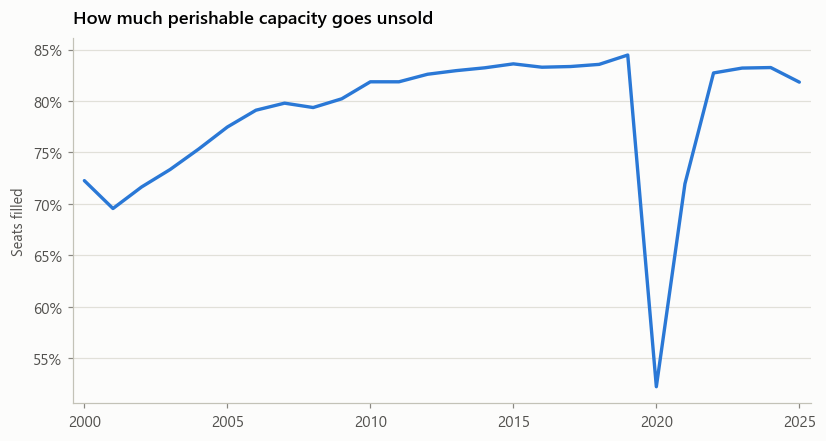


load factor: 72.3% (2000) -> 81.8% (2025)


In [3]:
LOAD = get(pick_fred("load factor air carriers domestic passenger",
                     ["load factor"], prefer=("LOAD", "TSI", "AIR"), forbid=("SMU", "SMS")),
           "Airline load factor", ["load factor"])

if LOAD is None:                       # widen the net once before giving up
    LOAD = get(pick_fred("air revenue passenger miles available seat miles",
                         ["load factor"], prefer=None, forbid=("SMU", "SMS")),
               "Airline load factor", ["load factor"])

if LOAD is not None:
    LOAD = LOAD[LOAD.index >= 1990]
    fig, ax = plt.subplots(figsize=(7.4, 3.9))
    ax.plot(LOAD.index, LOAD.values, color=sl.PALETTE[0], lw=2.2)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%d%%" % v))
    ax.set_ylabel("Seats filled")
    ax.set_xlim(LOAD.index.min() - 0.4, LOAD.index.max() + 0.4)
    ax.set_title("How much perishable capacity goes unsold")
    sl.save_fig(fig, "fig1_load_factor", DIRS)
    plt.show()
    print("\nload factor: %.1f%% (%d) -> %.1f%% (%d)"
          % (LOAD.iloc[0], LOAD.index[0], LOAD.iloc[-1], LOAD.index[-1]))
else:
    print("Section A skipped. Send back the search listing and it can be re-pointed.")

## Section B - displacement

The share of American retail spending that goes through electronic channels,
against employment in the format it displaced. This is the chapter's argument
where the national statistics can actually see it.

In [4]:
ECOM = get(pick_fred("e-commerce retail sales as a percent of total sales",
                     ["e-commerce", "percent"], prefer=("ECOM",), forbid=("SMU",),
                     freq_prefix="Q"),
           "E-commerce share of retail", ["e-commerce"])

JOBS = {}
for label, query, expect in [
    ("Electronic shopping and mail-order",
     "all employees electronic shopping and mail-order houses", ["electronic shopping"]),
    ("Department stores",
     "all employees department stores", ["department stores"]),
    ("Accommodation",
     "all employees accommodation", ["accommodation"]),
]:
    s = get(pick_fred(query, ["all employees"] + expect), label, ["all employees"] + expect)
    if s is not None:
        JOBS[label] = s

E = pd.DataFrame(JOBS).dropna(how="all")
E = E[E.index >= 1995]
print("\nemployment, thousands:")
print(E.round(1).tail(3).to_string())


e-commerce retail sales as a percent of total sales
        id                                               title freq from   to
 ECOMPCTSA E-Commerce Retail Sales as a Percent of Total Sales    Q 1999 2026
ECOMPCTNSA E-Commerce Retail Sales as a Percent of Total Sales    Q 1999 2026
FRED ECOMPCTSA: 107 obs, 1999-10-01-2026-04-01
  E-commerce share of retail     ECOMPCTSA            E-Commerce Retail Sales as a Percent of Total Sales
   dropped partial year(s) [1999, 2026] (had [1, 2] of 4 observations)

all employees electronic shopping and mail-order houses
   no candidate satisfied prefix ('CES', 'CEU') and title ['all employees', 'electronic shopping']
                    id                                                                                                           title freq from   to
  IPUHN45411W200000000       Employment for Retail Trade: Electronic Shopping and Mail-Order Houses (NAICS 45411) in the United States    A 1987 2025
   IPUHN4541W200000000        Emp

saved -> C:\Users\91838\Downloads\Stack_Article\11_why_platforms_excel\figures\fig2_displacement.png


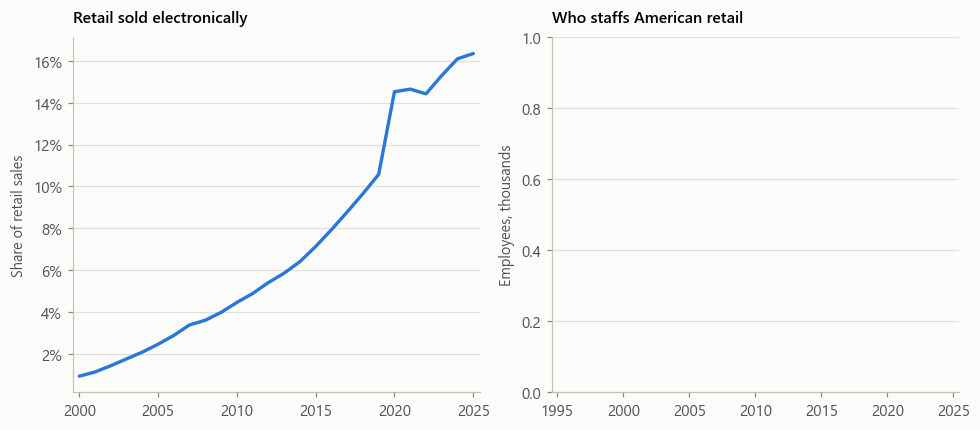

In [6]:
if ECOM is not None and len(E):
    fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.8))
    ec = ECOM[ECOM.index >= 1999]
    axes[0].plot(ec.index, ec.values, color=sl.PALETTE[0], lw=2.2)
    axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%d%%" % v))
    axes[0].set_ylabel("Share of retail sales")
    axes[0].set_xlim(ec.index.min() - 0.4, ec.index.max() + 0.4)
    axes[0].set_title("Retail sold electronically", fontsize=10.5)

    show = [c for c in ("Electronic shopping and mail-order", "Department stores")
            if c in E.columns]
    cols = dict(zip(show, [sl.PALETTE[2], sl.PALETTE[1]]))
    for c in show:
        s = E[c].dropna()
        axes[1].plot(s.index, s.values, color=cols[c], lw=2.2)
        axes[1].text(s.index[-1] - 9, s.iloc[-1] * (1.14 if c == show[0] else 0.80),
                     c.replace(" and mail-order", ""), color=cols[c],
                     fontsize=9, fontweight="semibold")
    axes[1].set_ylabel("Employees, thousands")
    axes[1].set_xlim(E.index.min() - 0.4, E.index.max() + 0.4)
    axes[1].set_title("Who staffs American retail", fontsize=10.5)
    sl.save_fig(fig, "fig2_displacement", DIRS)
    plt.show()

    for c in show:
        s = E[c].dropna()
        print("%-36s peak %7.1f (%d) -> %7.1f (%d)  %+.0f%%"
              % (c, s.max(), s.idxmax(), s.iloc[-1], s.index[-1],
                 (s.iloc[-1] / s.max() - 1) * 100))
else:
    print("Section B figure skipped; see the warnings above.")

## Section C - the extrapolation trap

The chapter's sharpest analytical claim, and it can be settled exactly rather
than argued. Suppose true demand decays exponentially:

    q(p) = Q0 * exp(-p / L)

Revenue is p * q(p), and its maximum sits at p = L exactly. That closed form
is the planted answer: if the numerical optimiser does not return L, the
optimiser is wrong and nothing below it can be trusted.

Now give an incumbent the price band it has historically charged, well above
L, and let it fit the straight line those observations support. Linear demand
a - b*p is revenue-maximised at a / 2b. The gap between that and L is the
chapter's argument in one number.

In [7]:
Q0, L = 1_000_000.0, 10.0            # true curve: scale and decay constant

def q_true(p):
    return Q0 * np.exp(-p / L)

grid = np.linspace(0.05, 120, 40000)
p_star_num = float(grid[np.argmax(grid * q_true(grid))])
assert abs(p_star_num - L) < 0.02, (p_star_num, L)
print("planted revenue-maximising price %.2f   optimiser returned %.4f   ok" % (L, p_star_num))

BANDS = [(30, 50), (40, 60), (50, 70)]
rows = []
for lo, hi in BANDS:
    obs = np.linspace(lo, hi, 7)
    b, a = np.polyfit(obs, q_true(obs), 1)          # q = a + b*p, b negative
    p_lin = -a / (2 * b)
    rows.append({"band": "$%d to $%d" % (lo, hi), "implied_optimum": p_lin,
                 "true_optimum": L, "ratio": p_lin / L,
                 "revenue_at_implied": p_lin * q_true(p_lin),
                 "revenue_at_true": L * q_true(L)})
T = pd.DataFrame(rows)
T["revenue_forgone_pct"] = (1 - T["revenue_at_implied"] / T["revenue_at_true"]) * 100
print("\nwhat an incumbent concludes from the prices it has charged:")
print(T[["band", "implied_optimum", "true_optimum", "ratio",
         "revenue_forgone_pct"]].round(2).to_string(index=False))

planted revenue-maximising price 10.00   optimiser returned 10.0001   ok

what an incumbent concludes from the prices it has charged:
      band  implied_optimum  true_optimum  ratio  revenue_forgone_pct
$30 to $50            25.45          10.0   2.54                45.70
$40 to $60            30.45          10.0   3.04                60.60
$50 to $70            35.45          10.0   3.54                72.17


saved -> C:\Users\91838\Downloads\Stack_Article\11_why_platforms_excel\figures\fig3_extrapolation_trap.png


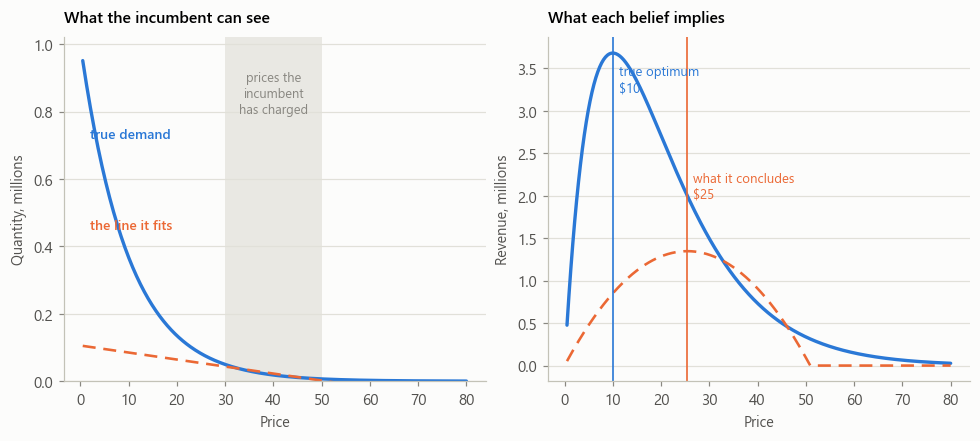

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.9))
ps = np.linspace(0.5, 80, 400)
axes[0].plot(ps, q_true(ps) / 1e6, color=sl.PALETTE[0], lw=2.2)
lo, hi = BANDS[0]
obs = np.linspace(lo, hi, 7)
b, a = np.polyfit(obs, q_true(obs), 1)
axes[0].plot(ps, (a + b * ps) / 1e6, color=sl.PALETTE[1], lw=1.7, ls=(0, (5, 3)))
axes[0].axvspan(lo, hi, color=sl.INK["grid"], alpha=0.7, lw=0, zorder=0)
axes[0].text((lo + hi) / 2, 0.92, "prices the\nincumbent\nhas charged", ha="center",
             va="top", fontsize=8.4, color=sl.INK["muted"], linespacing=1.3)
axes[0].text(2, 0.72, "true demand", color=sl.PALETTE[0], fontsize=9, fontweight="semibold")
axes[0].text(2, 0.45, "the line it fits", color=sl.PALETTE[1], fontsize=9, fontweight="semibold")
axes[0].set_ylim(0, 1.02)
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Quantity, millions")
axes[0].set_title("What the incumbent can see", fontsize=10.5)

rev_true = ps * q_true(ps)
rev_lin = ps * np.maximum(a + b * ps, 0)
axes[1].plot(ps, rev_true / 1e6, color=sl.PALETTE[0], lw=2.2)
axes[1].plot(ps, rev_lin / 1e6, color=sl.PALETTE[1], lw=1.7, ls=(0, (5, 3)))
axes[1].axvline(L, color=sl.PALETTE[0], lw=1.1)
axes[1].axvline(-a / (2 * b), color=sl.PALETTE[1], lw=1.1)
axes[1].text(L + 1.2, rev_true.max() / 1e6 * 0.96, "true optimum\n$%.0f" % L,
             color=sl.PALETTE[0], fontsize=8.6, va="top", linespacing=1.3)
axes[1].text(-a / (2 * b) + 1.2, rev_true.max() / 1e6 * 0.62,
             "what it concludes\n$%.0f" % (-a / (2 * b)),
             color=sl.PALETTE[1], fontsize=8.6, va="top", linespacing=1.3)
axes[1].set_xlabel("Price")
axes[1].set_ylabel("Revenue, millions")
axes[1].set_title("What each belief implies", fontsize=10.5)
sl.save_fig(fig, "fig3_extrapolation_trap", DIRS)
plt.show()

## Section D - pricing a two-sided market

Arithmetic, not evidence. Two sides, each with its own demand, and each made
more attractive by the size of the other:

    n_A = aA - bA * pA + g * n_B
    n_B = aB - bB * pB + g * n_A

with profit pA*nA + pB*nB. When the cross term g is zero the problem separates
into two textbook monopoly problems whose answers are aA/(2 bA) and aB/(2 bB).
That is the planted answer used to validate the solver before g is turned up.

In [9]:
aA, bA, aB, bB = 100.0, 2.0, 60.0, 0.6      # side A is the elastic side

def sides(pA, pB, g):
    """Solve the simultaneous system for participation on both sides."""
    det = 1 - g * g
    nA = ((aA - bA * pA) + g * (aB - bB * pB)) / det
    nB = ((aB - bB * pB) + g * (aA - bA * pA)) / det
    return nA, nB

def best_prices(g, span=(-200, 400), n=901):
    """
    Grid search, with a guard. An optimum sitting on the edge of the grid is not
    an optimum, it is a truncation, so the caller is told when that happens.
    """
    grid = np.linspace(*span, n)
    PA, PB = np.meshgrid(grid, grid, indexing="ij")
    nA, nB = sides(PA, PB, g)
    profit = np.where((nA > 0) & (nB > 0), PA * nA + PB * nB, -np.inf)
    i, j = np.unravel_index(np.argmax(profit), profit.shape)
    on_edge = i in (0, n - 1) or j in (0, n - 1)
    return grid[i], grid[j], profit[i, j], on_edge

pA0, pB0, _, _ = best_prices(0.0)
print("g = 0 check:  side A %.1f (expected %.1f)   side B %.1f (expected %.1f)"
      % (pA0, aA / (2 * bA), pB0, aB / (2 * bB)))
assert abs(pA0 - aA / (2 * bA)) < 1.0 and abs(pB0 - aB / (2 * bB)) < 1.0

# The system blows up as g approaches 1, where each side's demand becomes
# entirely a function of the other. Stop at 0.7, which is the last value whose
# optimum is still interior to the search grid.
gs = np.linspace(0.0, 0.7, 22)
opt = pd.DataFrame([dict(zip(("g", "pA", "pB", "profit", "on_edge"), (g,) + best_prices(g)))
                    for g in gs])
assert not opt["on_edge"].any(), "an optimum hit the grid edge; widen span in best_prices"
first_negative = opt.loc[opt["pA"] < 0, "g"].min() if (opt["pA"] < 0).any() else np.nan
print("\nside A's optimal price turns negative at cross-elasticity g = %s"
      % ("%.2f" % first_negative if np.isfinite(first_negative) else "never in this range"))
print(opt.drop(columns=["on_edge"]).round(2).to_string(index=False))

g = 0 check:  side A 24.7 (expected 25.0)   side B 50.0 (expected 50.0)

side A's optimal price turns negative at cross-elasticity g = 0.57
   g     pA     pB   profit
0.00  24.67  50.00  2749.78
0.03  24.67  50.67  2862.60
0.07  24.00  52.00  2985.21
0.10  23.33  53.33  3118.74
0.13  22.00  54.67  3264.94
0.17  21.33  56.00  3425.65
0.20  20.67  58.00  3602.85
0.23  19.33  60.00  3799.58
0.27  18.00  62.00  4018.97
0.30  17.33  64.00  4265.46
0.33  15.33  66.67  4544.33
0.37  14.00  69.33  4862.30
0.40  12.00  72.67  5228.00
0.43  10.00  76.67  5653.35
0.47   7.33  81.33  6154.15
0.50   4.00  87.33  6752.36
0.53   0.67  94.00  7479.43
0.57  -4.00 102.00  8382.40
0.60 -10.00 113.33  9533.33
0.63 -18.00 127.33 11051.03
0.67 -28.67 146.67 13143.47
0.70 -44.67 176.00 16214.00


saved -> C:\Users\91838\Downloads\Stack_Article\11_why_platforms_excel\figures\fig4_two_sided_pricing.png


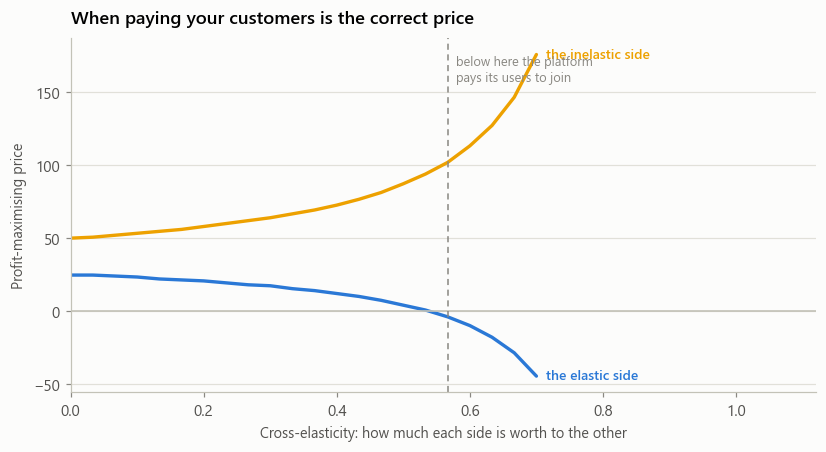

In [10]:
fig, ax = plt.subplots(figsize=(7.4, 4.0))
ax.plot(opt["g"], opt["pA"], color=sl.PALETTE[0], lw=2.2)
ax.plot(opt["g"], opt["pB"], color=sl.PALETTE[3], lw=2.2)
ax.axhline(0, color=sl.INK["axis"], lw=1.1)
ax.text(opt["g"].iloc[-1] + 0.015, opt["pA"].iloc[-1], "the elastic side",
        color=sl.PALETTE[0], fontsize=9, va="center", fontweight="semibold")
ax.text(opt["g"].iloc[-1] + 0.015, opt["pB"].iloc[-1], "the inelastic side",
        color=sl.PALETTE[3], fontsize=9, va="center", fontweight="semibold")
if np.isfinite(first_negative):
    ax.axvline(first_negative, color=sl.INK["muted"], lw=1.0, ls=(0, (4, 3)))
    ax.text(first_negative + 0.012, ax.get_ylim()[1] * 0.94,
            "below here the platform\npays its users to join",
            color=sl.INK["muted"], fontsize=8.4, va="top", linespacing=1.3)
ax.set_xlim(0, 1.12)
ax.set_xlabel("Cross-elasticity: how much each side is worth to the other")
ax.set_ylabel("Profit-maximising price")
ax.set_title("When paying your customers is the correct price")
sl.save_fig(fig, "fig4_two_sided_pricing", DIRS)
plt.show()

## Section E - lodging, and what a national series cannot see

Zervas and Proserpio found Airbnb cut Austin hotel revenue by 10 percent over
five years, with the damage concentrated in lower-priced hotels and those not
serving business travellers. National monthly series carry no price tier and
no city, so they cannot reproduce that result.

What they can do is answer a weaker question honestly: did hotel prices break
away from services prices in general once home-sharing scaled? A placebo runs
the identical test on a service with no platform substitute. If the placebo
moves too, the test measures nothing.

In [11]:
CPI = {}
for label, query, expect in [
    ("Hotels and motels", "consumer price index other lodging away from home including hotels and motels",
     ["lodging"]),
    ("All services", "consumer price index services", ["services"]),
    ("Dental services (placebo)", "consumer price index dental services", ["dental"]),
]:
    s = get(pick_fred(query, ["consumer price index"] + expect,
                      prefer=("CUSR", "CUUR", "CPI"), forbid=("SMU", "SMS", "CUUS")),
            label, expect)
    if s is not None:
        CPI[label] = s

X = pd.DataFrame(CPI).dropna(how="all")
X = X[(X.index >= 2000) & (X.index <= int(X.index.max()))]
if len(X.columns) >= 2:
    BASE = 2010                                  # Airbnb's scaling begins
    Xi = X.div(X.loc[BASE], axis=1) * 100
    fig, ax = plt.subplots(figsize=(7.6, 4.0))
    cols = dict(zip(Xi.columns, [sl.PALETTE[1], sl.INK["secondary"], sl.PALETTE[2]]))
    for c in Xi.columns:
        ax.plot(Xi.index, Xi[c].values, color=cols[c], lw=2.1)
        sl.label_last(ax, Xi[c], c, cols[c], dx=0.3, fontsize=9)
    ax.axvline(BASE, color=sl.INK["axis"], lw=1.0, ls=(0, (4, 3)))
    ax.set_ylabel("Price index, %d = 100" % BASE)
    ax.set_xlim(Xi.index.min() - 0.4, Xi.index.max() + 9)
    ax.set_title("Did hotel prices break away?")
    sl.save_fig(fig, "fig5_lodging", DIRS)
    plt.show()

    print("\nannualised change, %d to %d:" % (BASE, int(Xi.index.max())))
    for c in Xi.columns:
        s = Xi[c].dropna()
        yrs = s.index[-1] - BASE
        print("  %-28s %+.2f%% a year" % (c, ((s.iloc[-1] / 100) ** (1 / yrs) - 1) * 100))
else:
    Xi = pd.DataFrame()
    print("Section E skipped; fewer than two price series resolved.")

No FRED series matched 'consumer price index other lodging away from home including hotels and motels'

consumer price index other lodging away from home including hotels and motels
   nothing returned
WARNING  Hotels and motels: no candidates; skipped.

consumer price index services
           id                                                                                                            title freq from   to
 CUSR0000SAM2                         Consumer Price Index for All Urban Consumers: Medical Care Services in U.S. City Average    M 1956 2026
  CUSR0000SAS                                      Consumer Price Index for All Urban Consumers: Services in U.S. City Average    M 1956 2026
CUSR0000SASLE                 Consumer Price Index for All Urban Consumers: Services Less Energy Services in U.S. City Average    M 1967 2026
 CUSR0000SEHG Consumer Price Index for All Urban Consumers: Water and Sewer and Trash Collection Services in U.S. City Average    M 1997 2026
 CUSR

## Payload

In [12]:
payload = {
    "resolved_series": RESOLVED,
    "extrapolation": {
        "true_optimum": L,
        "optimiser_returned": p_star_num,
        "bands": T.round(4).to_dict(orient="records"),
    },
    "two_sided": {
        "params": {"aA": aA, "bA": bA, "aB": aB, "bB": bB},
        "monopoly_check": {"pA": float(pA0), "pB": float(pB0),
                           "expected_pA": aA / (2 * bA), "expected_pB": aB / (2 * bB)},
        "first_negative_g": (float(first_negative) if np.isfinite(first_negative) else None),
        "curve": opt.drop(columns=["on_edge"]).round(4).to_dict(orient="records"),
    },
}
if LOAD is not None:
    payload["load_factor"] = {"first": float(LOAD.iloc[0]), "first_year": int(LOAD.index[0]),
                              "last": float(LOAD.iloc[-1]), "last_year": int(LOAD.index[-1])}
if ECOM is not None:
    e = ECOM.dropna()
    payload["ecommerce_share"] = {"first": float(e.iloc[0]), "first_year": int(e.index[0]),
                                  "last": float(e.iloc[-1]), "last_year": int(e.index[-1])}
if len(E):
    payload["employment"] = {c: {"peak": float(E[c].dropna().max()),
                                 "peak_year": int(E[c].dropna().idxmax()),
                                 "latest": float(E[c].dropna().iloc[-1]),
                                 "latest_year": int(E[c].dropna().index[-1])}
                             for c in E.columns}
if len(Xi):
    payload["lodging_index"] = {c: {int(k): float(v) for k, v in Xi[c].dropna().items()}
                                for c in Xi.columns}

sl.write_findings(payload, DIRS)
if len(E):
    E.to_csv(pathlib.Path(DIRS["findings"]) / "employment.csv")
if len(Xi):
    Xi.to_csv(pathlib.Path(DIRS["findings"]) / "lodging_prices.csv")
opt.drop(columns=["on_edge"]).to_csv(
    pathlib.Path(DIRS["findings"]) / "two_sided_prices.csv", index=False)
T.to_csv(pathlib.Path(DIRS["findings"]) / "extrapolation_bands.csv", index=False)

print(json.dumps({k: v for k, v in payload.items()
                  if k not in ("lodging_index", "two_sided")}, indent=2)[:2400])

findings -> C:\Users\91838\Downloads\Stack_Article\11_why_platforms_excel\findings\headline_numbers.json
{
  "resolved_series": {
    "Airline load factor": {
      "id": "LOADFACTOR",
      "title": "Load Factor for U.S. Air Carrier Domestic and International, Scheduled Passenger Flights"
    },
    "E-commerce share of retail": {
      "id": "ECOMPCTSA",
      "title": "E-Commerce Retail Sales as a Percent of Total Sales"
    },
    "Accommodation": {
      "id": "CES7072100001",
      "title": "All Employees, Accommodation"
    },
    "All services": {
      "id": "CUSR0000SAM2",
      "title": "Consumer Price Index for All Urban Consumers: Medical Care Services in U.S. City Average"
    }
  },
  "extrapolation": {
    "true_optimum": 10.0,
    "optimiser_returned": 10.000101252531314,
    "bands": [
      {
        "band": "$30 to $50",
        "implied_optimum": 25.4468,
        "true_optimum": 10.0,
        "ratio": 2.5447,
        "revenue_at_implied": 1997532.8999,
        "rev

## What to send back

The PNGs in `figures/`, `findings/headline_numbers.json`, and the printed
search listings from every `pick_fred` call. If a section printed a WARNING,
that listing is what lets the query be re-pointed without rerunning the
notebook.